# Учебный кейс: исследовательский анализ данных
*Шаблон для выполнения задания*

**Датасет:** [Used Car Price Prediction Dataset](https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset)

## 📊 Описание датасета

В данном задании используется датасет с информацией о продаже подержанных автомобилей, собранной из объявлений.
Датасет содержит 12 признаков. Каждая строка — одно объявление о продаже автомобиля.

**Бизнес-контекст:** вы — аналитик в автодилерской компании. Нужно провести исследовательский анализ данных (EDA) — понять, что находится в датасете, и оценить качество данных.

**Описание признаков:**
- `brand` — марка автомобиля (BMW, Ford, Toyota, …)
- `model` — модель автомобиля
- `model_year` — год выпуска
- `milage` — пробег (мили)
- `fuel_type` — тип топлива (Gasoline, Hybrid, E85 Flex Fuel, Diesel, …)
- `engine` — двигатель (строка: объём, мощность, тип)
- `transmission` — коробка передач (Automatic, Manual, CVT, …)
- `ext_col` — цвет кузова
- `int_col` — цвет салона
- `accident` — были ли ДТП (None / At least 1 accident or damage reported)
- `clean_title` — чистое ли свидетельство о регистрации (Yes / NaN)
- `price` — цена (USD, строка с символом $)



## 1. Импорт библиотек и загрузка данных

Импортируйте библиотеки, которые понадобятся для работы.
Вам точно понадобятся: `pandas`, `matplotlib.pyplot`, `seaborn`.
Опционально (для бонусных задач): `phik`, `missingno`.

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns
import phik
from phik.report import plot_correlation_matrix
path = kagglehub.dataset_download("taeefnajib/used-car-price-prediction-dataset")
df = pd.read_csv(f"{path}/used_cars.csv")
df.head()

C:\Users\danil\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [2]:
df.sample(5, random_state=42)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
2580,Lexus,IS 300 Base,2018,"50,992 mi.",Gasoline,260.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,White,Gray,At least 1 accident or damage reported,Yes,"$28,000"
3660,Chevrolet,Impala Base,2004,"64,500 mi.",Gasoline,180.0HP 3.4L V6 Cylinder Engine Gasoline Fuel,A/T,Beige,Beige,None reported,Yes,"$5,900"
897,RAM,2500 SLT,2017,"86,000 mi.",Diesel,350.0HP 6.7L Straight 6 Cylinder Engine Diesel...,6-Speed A/T,Gray,Gray,At least 1 accident or damage reported,Yes,"$41,000"
2091,Mercedes-Benz,SL-Class SL 550,2013,"24,933 mi.",Gasoline,429.0HP 4.6L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Silver,Red,At least 1 accident or damage reported,Yes,"$40,250"
1044,Ford,Shelby GT350R Base,2018,"18,500 mi.",Gasoline,526.0HP 5.2L 8 Cylinder Engine Gasoline Fuel,M/T,Blue,Black,At least 1 accident or damage reported,Yes,"$77,999"


## 2. Первичный осмотр данных

Проведите инвентаризацию датасета. Ответьте на вопросы:
- Сколько строк?
- Какие типы данных у каждого столбца? Есть ли неожиданные типы?
- Как выглядят базовые статистики по признаками?
- Какие «красные флаги» вы замечаете уже на этом этапе?

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [4]:
df.describe()

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [5]:
df[df['fuel_type'].isna()]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
9,Tesla,Model X Long Range Plus,2020,"34,000 mi.",NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,"$69,950"
44,Lucid,Air Grand Touring,2022,"3,552 mi.",NaN,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Red,Beige,None reported,Yes,"$119,999"
68,Lucid,Air Grand Touring,2022,"4,900 mi.",NaN,536.0HP Electric Motor Electric Fuel System,1-Speed A/T,Red,Black,None reported,Yes,"$99,000"
92,Rivian,R1S Adventure Package,2023,"2,800 mi.",NaN,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,White,Green,None reported,Yes,"$92,000"
122,Rivian,R1S Adventure Package,2023,"2,500 mi.",NaN,835.0HP Electric Motor Electric Fuel System,A/T,Green,White,None reported,Yes,"$94,000"
...,...,...,...,...,...,...,...,...,...,...,...,...
3908,Tesla,Model Y Long Range,2021,"49,252 mi.",NaN,Electric,1-Speed Automatic,Deep Blue Metallic,Black,None reported,NaN,"$37,999"
3913,Tesla,Model S 100D,2018,"65,000 mi.",NaN,518.0HP Electric Motor Electric Fuel System,A/T,Blue,Black,None reported,Yes,"$41,000"
3932,Tesla,Model X Performance,2020,"25,535 mi.",NaN,778.0HP Electric Motor Electric Fuel System,A/T,White,Beige,None reported,Yes,"$68,969"
3961,Tesla,Model 3 Long Range,2021,"23,749 mi.",NaN,Electric,1-Speed Automatic,White,Black,None reported,NaN,"$35,999"


## Наблюдения по первичному осмотру:

Датасет имеет 11 признаков и 4009 записей.

Числовые признаки: `model_year`, `mileage`, `price`

Категориальные признаки: `fuel_type`, `transmission`, `accident`, `clean_title`

Подготовка данных:

`mileage` и `price` хранятся в str, нужно будет преобразовать в int.

Признаки `engine` и `transmission` для анализа можно будет распарсить если понадобится статистики по лошадиным силам и типам трансмиссии

Базовые статистики посчитать без приведения типов получится только для года выпуска

Красные флаги:
`fuel_type` имеет пропуски в значениях где тип двигателя электро

## 3. Качество данных: пропуски и дубликаты

Исследуйте полноту и чистоту данных:
- В каких столбцах есть пропуски? Какова их доля (в %)?
- Есть ли полные дубликаты строк?
- Есть ли частичные дубликаты?
- Какие решения вы принимаете по каждому типу проблемы?


💡 *Бонус (необязательное задание):* попробуйте библиотеку `missingno` для визуализации пропусков.

## Исследуем пропуски:

### Общее число пропусков:

In [6]:
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%
clean_title,596,14.87
fuel_type,170,4.24
accident,113,2.82


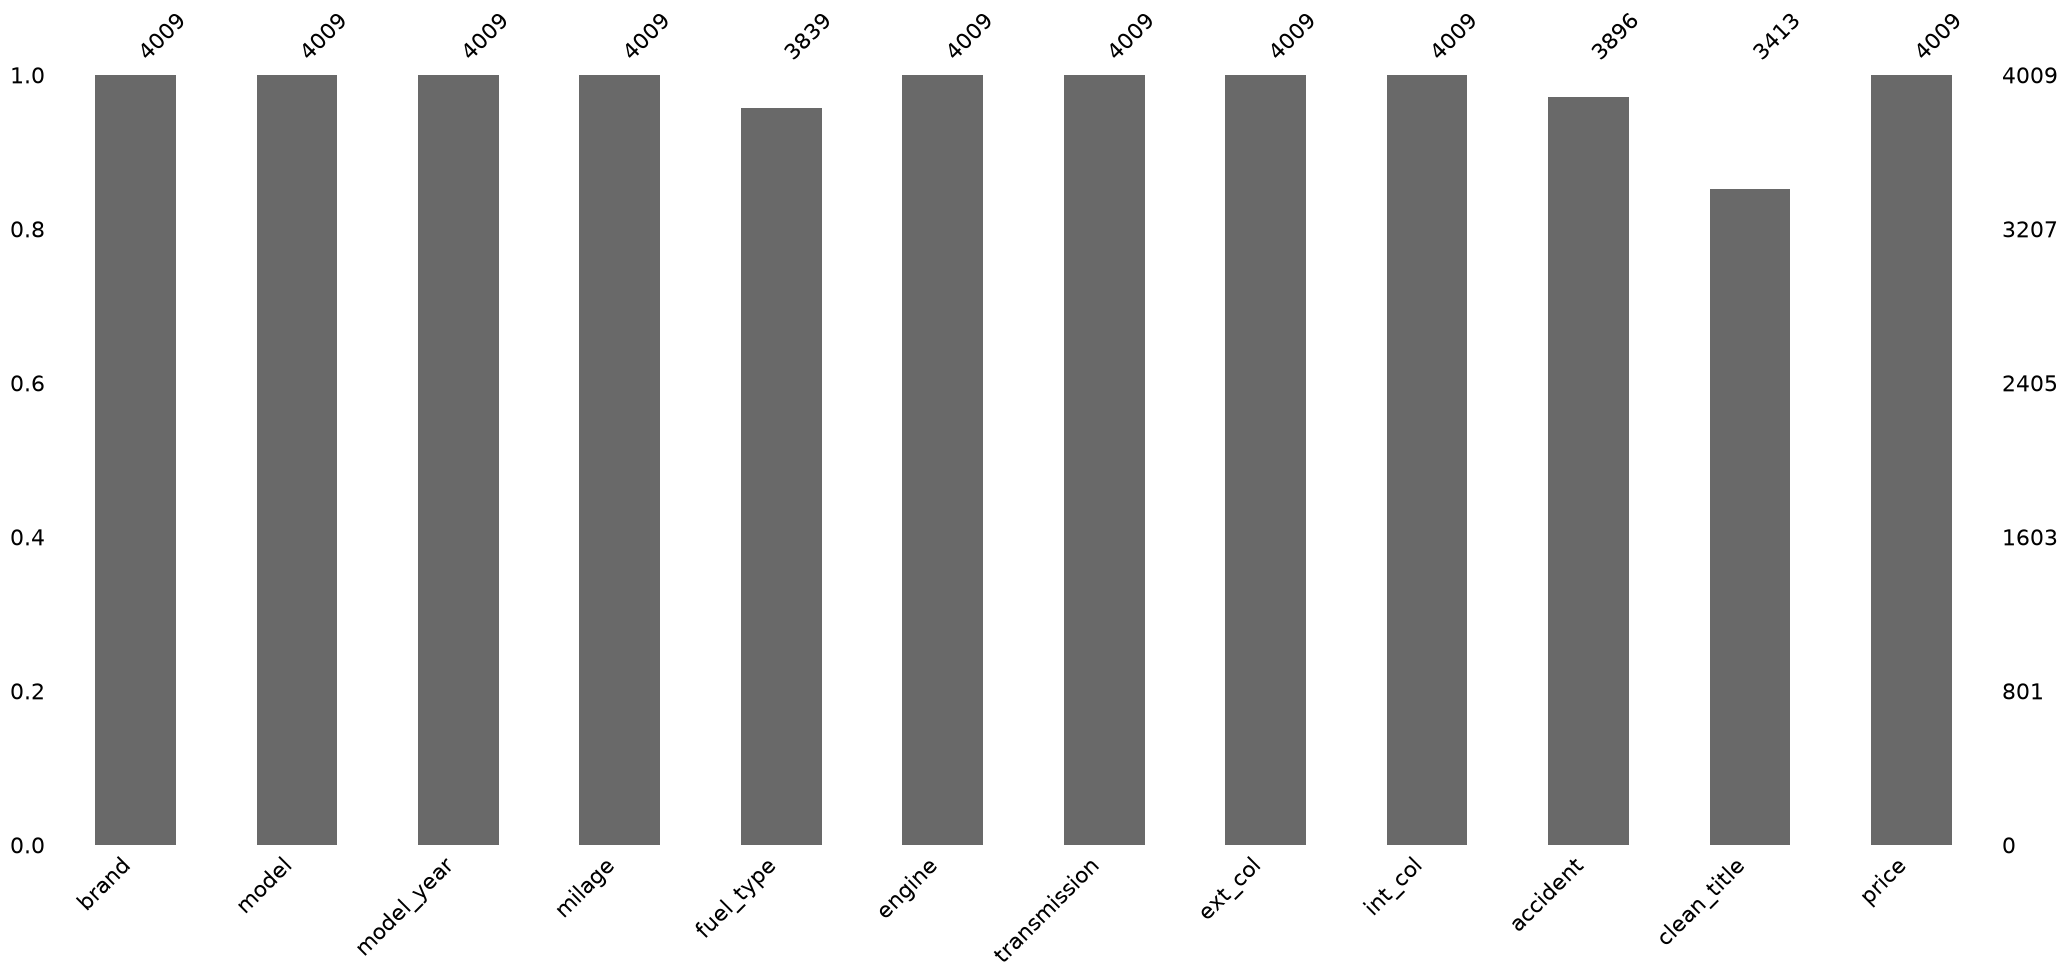

In [7]:
msno.bar(df)
plt.show()

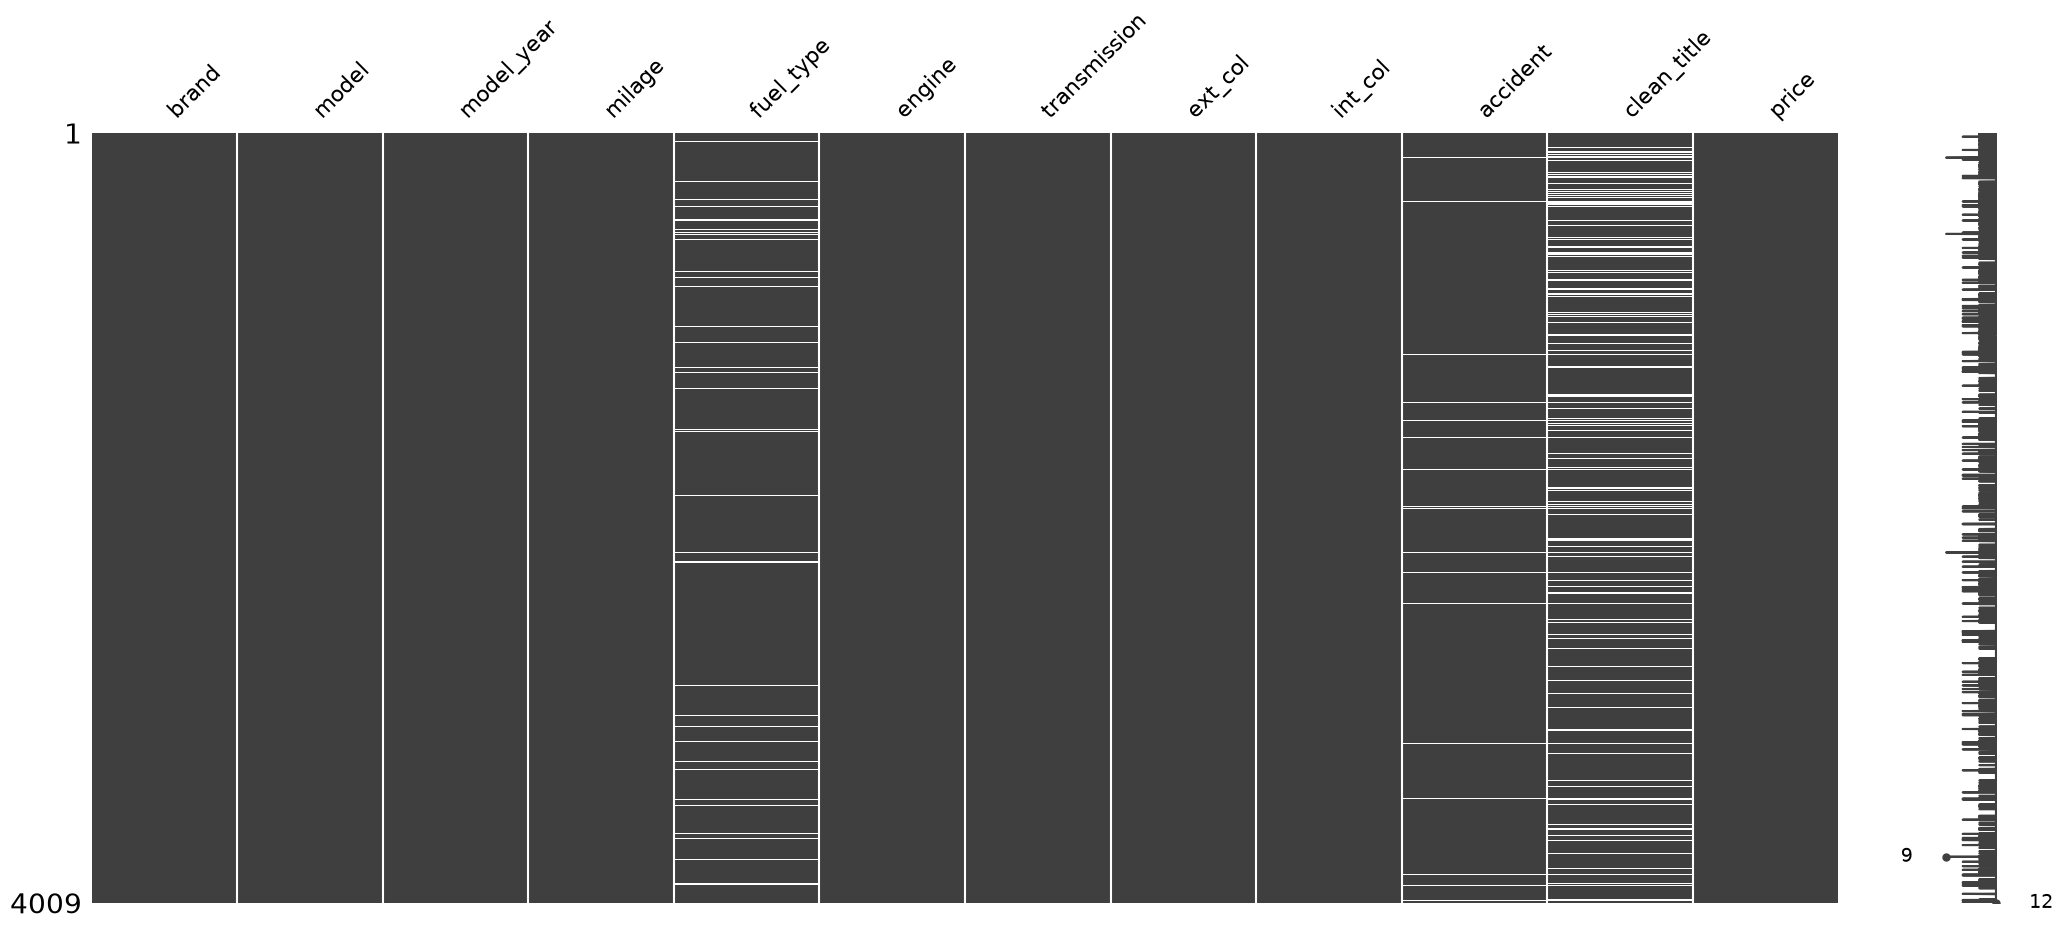

In [8]:
msno.matrix(df)
plt.show()

## Пропуски в `clean_title`:

Пропуски в `clean_title` это "не чистое свидетельство" 

Из информации о датасете

## Пропуски в `fuel_type`:

Предположу, что все машины с пропуском в `fuel_type` это машины с электродвигателем

In [9]:
missing_fuel = df[df['fuel_type'].isna()]

hypothesis_confirmed = missing_fuel['engine'].str.contains('electric', case=False, na=False).all()

print("Гипотеза подтверждена:", hypothesis_confirmed)

Гипотеза подтверждена: False


In [10]:
exceptions = missing_fuel[~missing_fuel['engine'].str.contains('electric', case=False, na=False)]

print('Нашел исключения в гипотезе:')
print(exceptions[['brand', 'model', 'engine']])

Нашел исключения в гипотезе:
      brand                  model                               engine
383    Ford  Mustang Mach-E Select               Standard Range Battery
456     Kia               EV6 Wind  111.2Ah / FR 70kW / RR 160kW (697V)
555   Tesla     Model 3 Long Range                Dual Motor - Standard
1800  Tesla     Model Y Long Range                Dual Motor - Standard
2613  Tesla     Model Y Long Range                Dual Motor - Standard


Проверив эти 5 машин убедился, что они все электро автомобили

### Гипотеза подтверждена

## Пропуски в `accident`:

Предположу, что все пропуски по признаку `accident` это машины у которых в признаке `clean_title` также стоит `NaN`

In [11]:
missing_accident = df[df['accident'].isna()]

is_all_nan = missing_accident['clean_title'].isna().all()

print("Все clean_title также NaN:", is_all_nan)

Все clean_title также NaN: True


Проверим есть ли автомобили без дтп, но с нечистым свидетельством

In [12]:
no_accident = df['clean_title'].isna() & (df['accident'] == 'None')
has_cars = no_accident.any()
print("Есть такие автомобили:", has_cars)

Есть такие автомобили: False


Посмотрим на корреляцию между пропусками

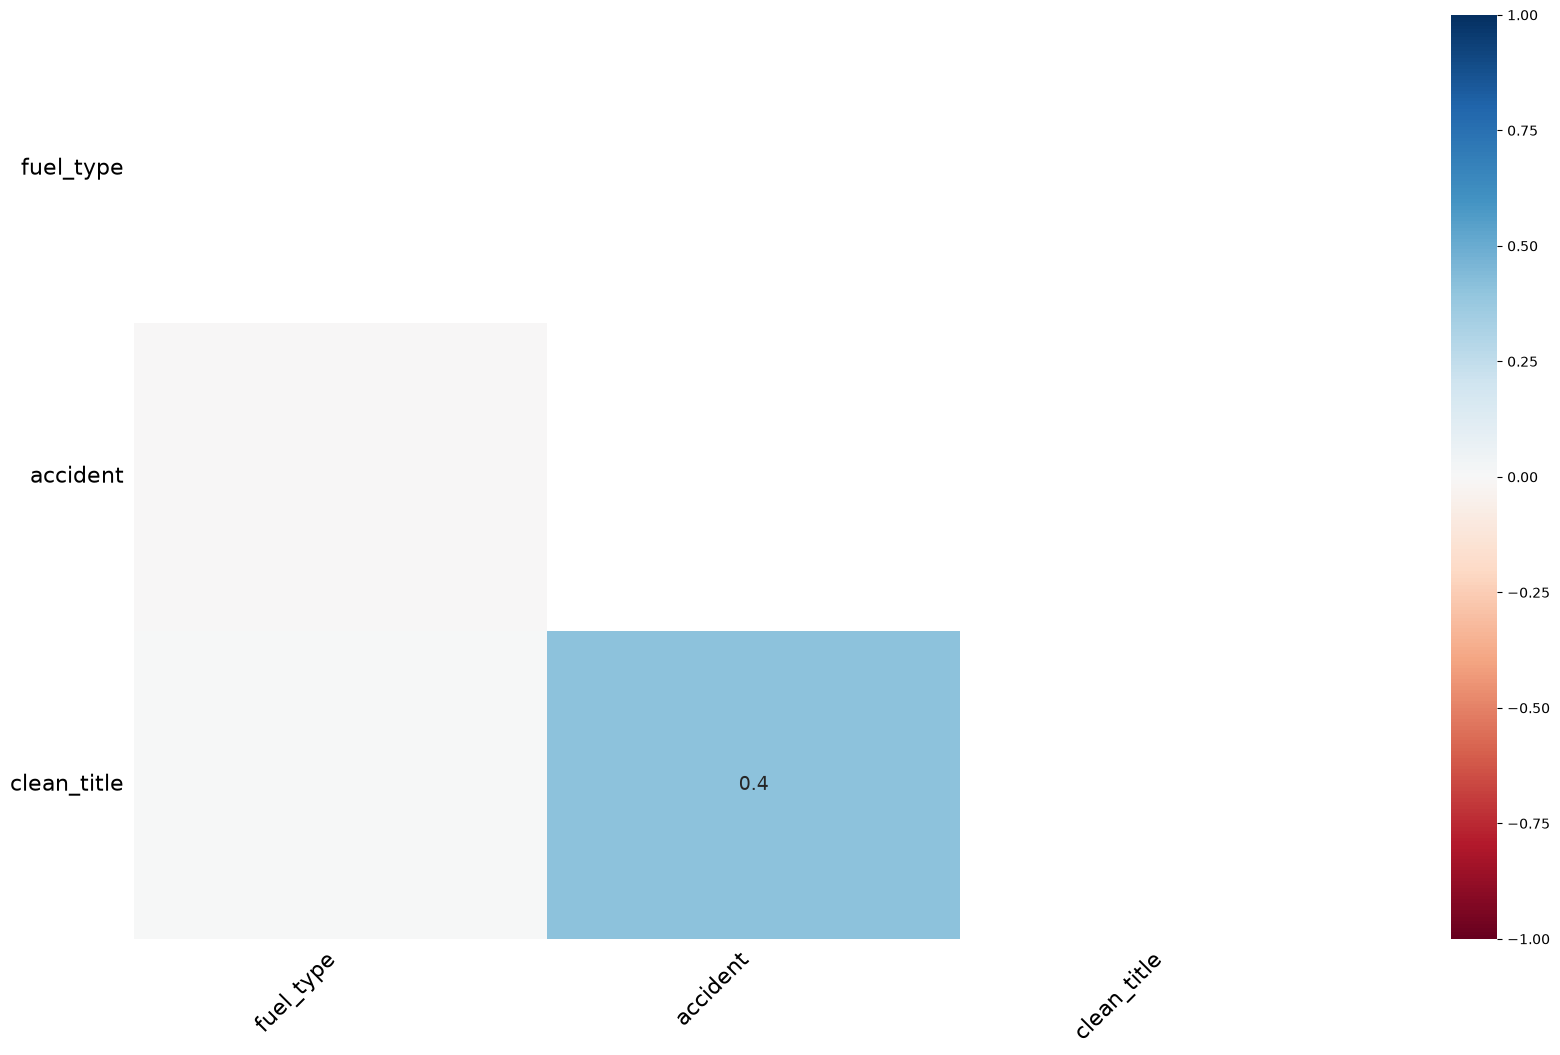

In [13]:
msno.heatmap(df)
plt.show()

Между признаком `accident` и `clean_title` есть умеренная положительная связь, хотя пропусков у `clean_title` больше

In [14]:
print("Полные дубликаты строк:")
df[df.duplicated()]

Полные дубликаты строк:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


In [15]:
count_name_dups = df.duplicated(subset=['model_year', 'milage','model']).sum()

print(f"Найдено частичных дубликатов: {count_name_dups}")

df[df.duplicated(subset=['model_year', 'milage','price'], keep=False)]

Найдено частичных дубликатов: 3


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


In [16]:
count_name_dups = df.duplicated(subset=['price', 'milage','model']).sum()

print(f"Найдено частичных дубликатов: {count_name_dups}")

df[df.duplicated(subset=['price', 'milage','model'], keep=False)]

Найдено частичных дубликатов: 0


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


# Вывод

## Пропуски:

Признак `clean_title` имеет 596 пропусков (14.87%) но все эти пропуски это не чистое свидетельство о регистрации -> заменим во всем датасете `NaN` на `No`

Признак `fuel_type` имеет 170 пропусков (4.24%) но все эти пропуски это электромобили -> заменим `NaN` на `Electric`

Признак `accident` имеет 113 пропусков (2.82%) но все эти пропуски это автомобили у которых в признаке `clean_title` также указан NaN. С тем что автомобилей без дтп и с не чистым свидетельством в датасете нет, также учитывая умеренно положительную корреляцию между этими признаками как видно на тепловой карте, осмелюсь предположить, что эти машины были в дтп, но потеряли свои значения -> заменим `NaN` на `At least 1 accident or damage reported`

## Дубликаты:

Полных дубликатов строк нет вообще

Частичных дубликатов по срезу `model_year` `milage` `model` - найдено 3 штуки, но если в срезе `model_year` или `model` заменить на `price` все дубликаты сразу пропадают

Сделаю предположение что частичных дубликатов также нет это разные объявления с похожими характеристиками автомобилей

## 4. Очистка и подготовка данных

Подготовьте данные к анализу:
- Преобразуйте столбцы с некорректными типами
- Обработайте пропуски (заполните, удалите или оставьте — с обоснованием)
- При необходимости удалите ненужные столбцы


#### В `milage` оставляем только цифры и приводим к числовому типу

In [17]:
df_clean = df.copy()
df_clean['milage'] = (
    df_clean['milage']
    .astype(str)
    .str.replace('mi.', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

#### В `price` оставляем только цифры и приводим к числовому типу

In [18]:
df_clean['price'] = (
    df_clean['price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

#### Пропуски заполняем в соответсвии с предыдущим пунктом

In [19]:
df_clean['fuel_type'] = df_clean['fuel_type'].fillna('Electric')

df_clean['accident'] = df_clean['accident'].fillna('At least 1 accident or damage reported')

df_clean['clean_title'] = df_clean['clean_title'].fillna('No')

In [20]:
print("Информация о датасете после предобработки:")
print(df_clean.info())
print()
print("Проверка оставшихся пропусков:")
print(df_clean.isna().sum())

Информация о датасете после предобработки:
<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   str    
 1   model         4009 non-null   str    
 2   model_year    4009 non-null   int64  
 3   milage        4009 non-null   float64
 4   fuel_type     4009 non-null   str    
 5   engine        4009 non-null   str    
 6   transmission  4009 non-null   str    
 7   ext_col       4009 non-null   str    
 8   int_col       4009 non-null   str    
 9   accident      4009 non-null   str    
 10  clean_title   4009 non-null   str    
 11  price         4009 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 376.0 KB
None

Проверка оставшихся пропусков:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0


## 5. Анализ распределений

Исследуйте, как распределены числовые признаки:
- Постройте гистограммы для ключевых числовых признаков
- Есть ли скошенность распределений? Где находится основная масса значений?
- Сравните среднее и медиану — сильно ли они различаются?
- Постройте boxplot для поиска выбросов

💡 Инструменты: `.hist()`, `sns.histplot()`, `sns.boxplot()`, `plt.subplots()`, `.axvline()` для mean/median, `.mean()`, `.median()`, `.quantile()`.

In [21]:
key_cols = ['price', 'milage', 'model_year']

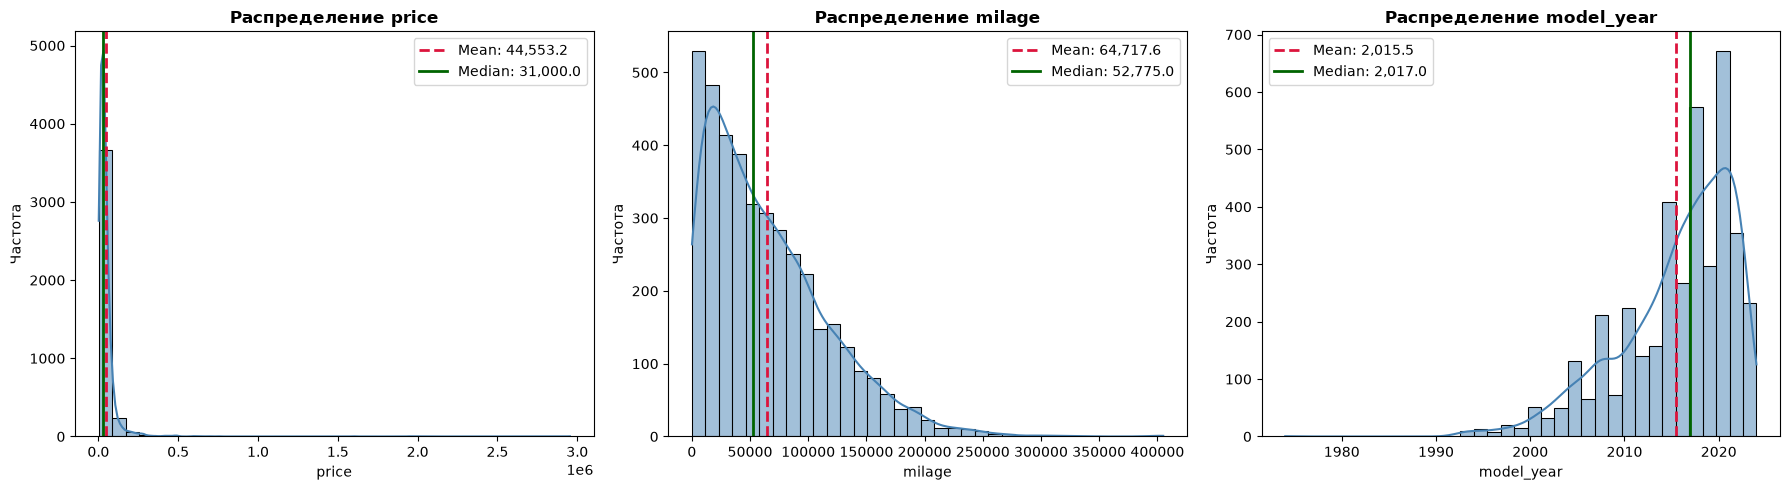

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, key_cols):
    mean_val = df_clean[col].mean()
    median_val = df_clean[col].median()
    
    sns.histplot(df_clean[col], kde=True, ax=ax, bins=35, color='steelblue')
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {mean_val:,.1f}')
    ax.axvline(median_val, color='darkgreen', linestyle='-', linewidth=2, label=f'Median: {median_val:,.1f}')
    
    ax.set_title(f'Распределение {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Частота')
    ax.legend()

plt.tight_layout()
plt.show()

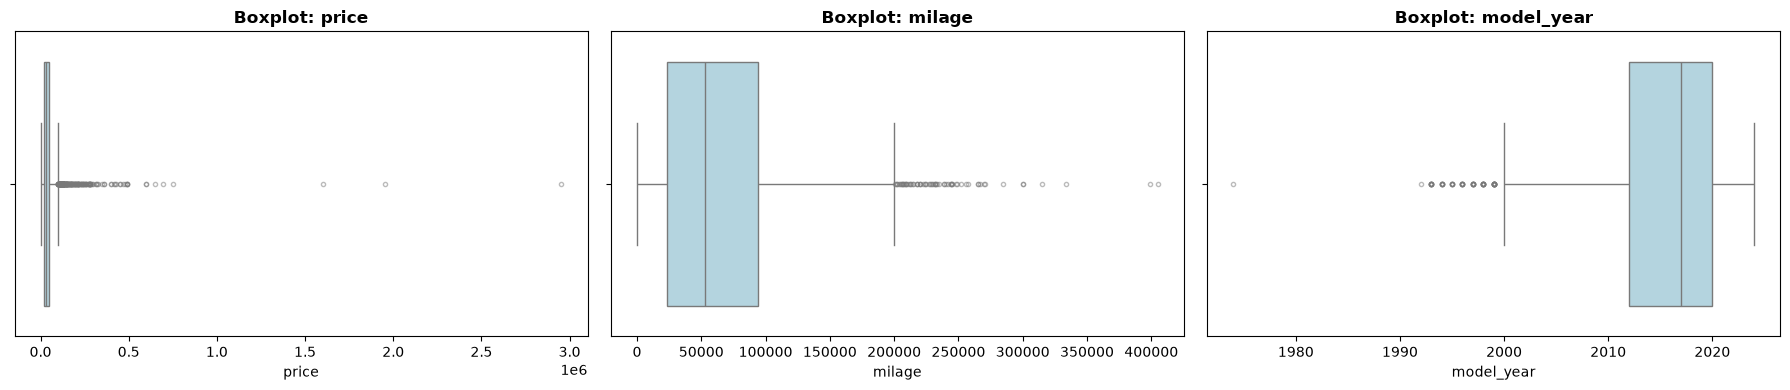

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, col in zip(axes, key_cols):
    sns.boxplot(x=df_clean[col], ax=ax, color='lightblue', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.5})
    ax.set_title(f'Boxplot: {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

### Цена сильно выбивается из-за единичных дорогих суперкаров, построим распределения исключая 99 квартиль, чтобы отсечь эти машины

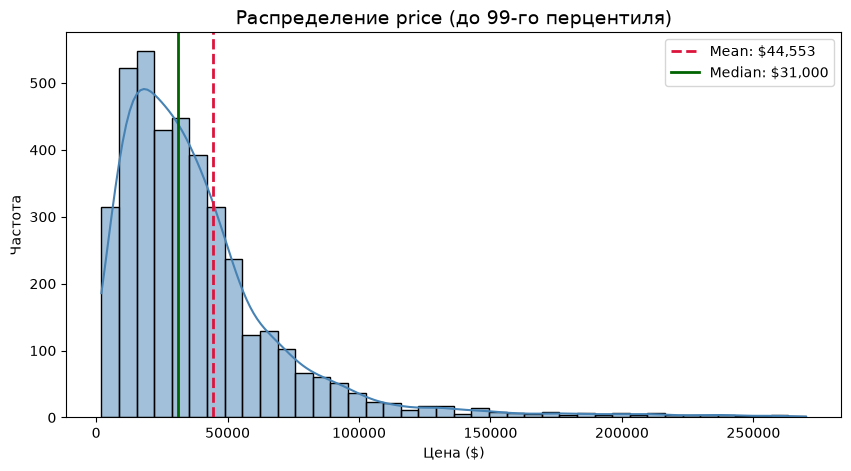

In [24]:
plt.figure(figsize=(10, 5))

q99_price = df_clean['price'].quantile(0.99)
mean_price = df_clean['price'].mean()
median_price = df_clean['price'].median()

sns.histplot(
    df_clean[df_clean['price'] <= q99_price]['price'],
    kde=True,
    bins=40,
    color='steelblue',
)

plt.axvline(mean_price, color='crimson', linestyle='--', linewidth=2, label=f'Mean: ${mean_price:,.0f}')
plt.axvline(median_price, color='darkgreen', linestyle='-', linewidth=2, label=f'Median: ${median_price:,.0f}')
plt.title('Распределение price (до 99-го перцентиля)', fontsize=14)
plt.xlabel('Цена ($)')
plt.ylabel('Частота')
plt.legend()
plt.show()

## Выводы по распределениям:

### Цена:
* Скошенность: ярко выраженная правосторонняя скошенность
* Основная масса значений сосредоточенна в диапозоне бюджетных и среднеценовых авто от 15,000 до 50,000
* Среднее существенно выше медианы, что обусловленно единичными дорогими суперкарами
* Есть выбросы справа от верхнего уса, это как раз дорогие автомобили

### Пробег:
* Скошенность: умеренная правосторонняя скошенность
* Основная масса значения сосредоточенна в пределах от 20,000 до 90,000 миль
* Среднее немного превышает медиану из-за длинного правого хвоста машин с большими пробегами
* Есть редкие автомобили с экстремальными пробегами больше 300,000 - это выбросы

### Год выпуска:
* Скошенность: левосторонняя скошенность
* Основная масса значений состредоточена в более новых годах выпуска 2015 - 2022
* Медиана на 2 года выше среднего
* Небольшое кол-во выбросов автомобилей раритетов менее 2000 года

## 6. Категориальный анализ и поиск взаимосвязей

Исследуйте категориальные признаки и связи между переменными:
- Какие марки авто представлены чаще всего?
- Как распределены типы топлива, КПП, история ДТП?
- Как цена зависит от года выпуска, пробега, марки?
- Есть ли различия в ценах между авто с ДТП и без?
- Постройте корреляционную матрицу — какие признаки сильнее всего связаны с ценой?


💡 *Бонус (необязательное задание):* попробуйте корреляцию φk через `.phik_matrix(interval_cols=)` из библиотеки `phik` — она работает с категориальными признаками лучше, чем Пирсон.

## Топ 10 марок авто

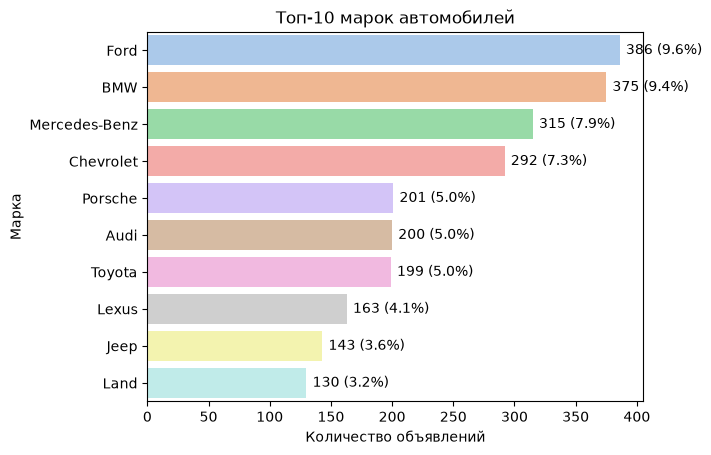

In [25]:
top_brands = df_clean['brand'].value_counts().head(10)

sns.barplot(
    x=top_brands.values,
    y=top_brands.index,
    hue=top_brands.index,
    palette='pastel',
    legend=False,
)

plt.title('Топ-10 марок автомобилей', fontsize=12)
plt.xlabel('Количество объявлений')
plt.ylabel('Марка')
for i, v in enumerate(top_brands.values):
  plt.text(v + 5, i, f'{v} ({v / len(df_clean):.1%})', va='center')
plt.show()

## Распределения типов топлива, КПП, истории ДТП

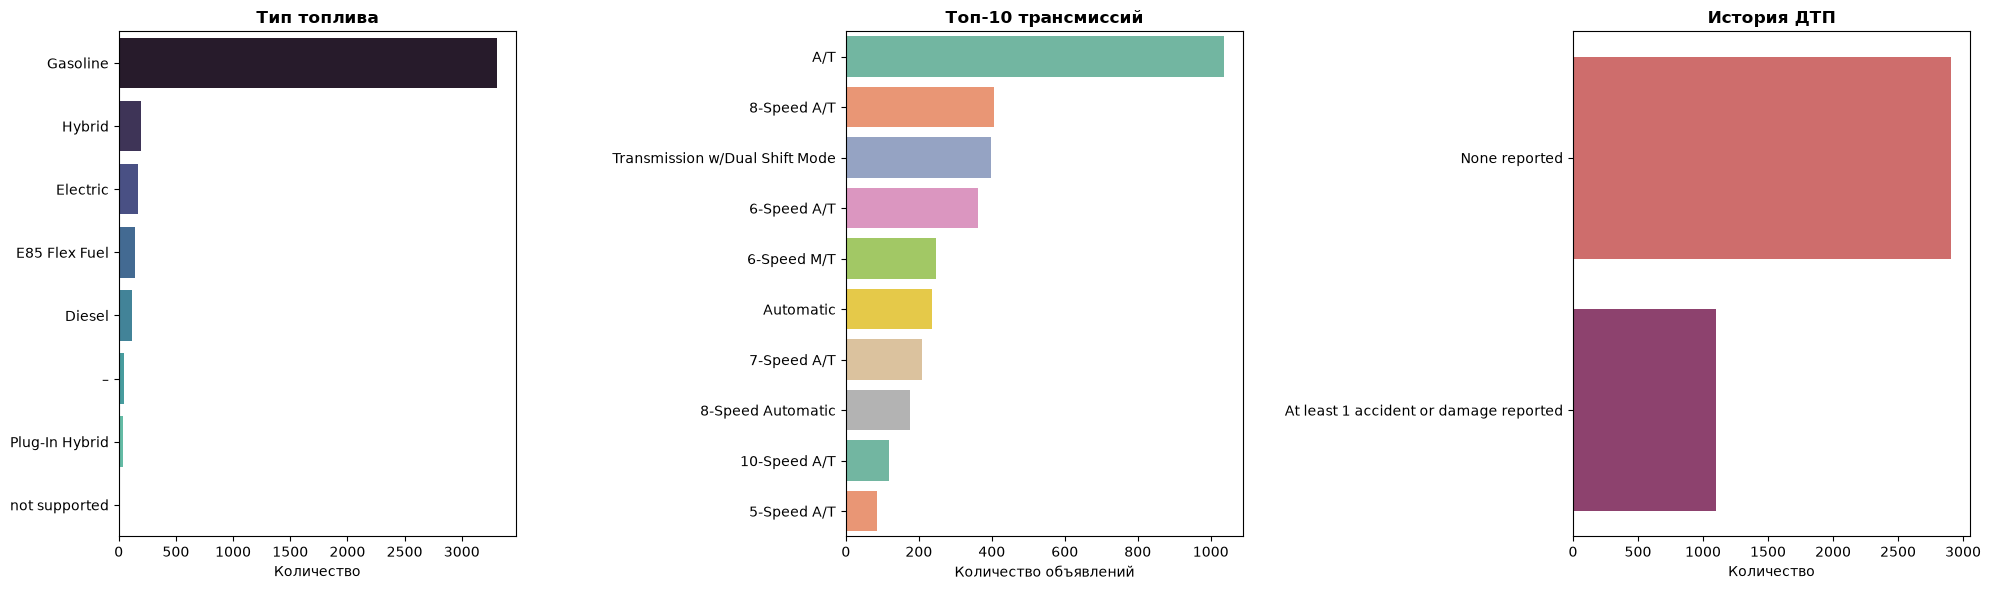

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

fuel_counts = df_clean['fuel_type'].value_counts()
sns.barplot(
    x=fuel_counts.values,
    y=fuel_counts.index,
    ax=axes[0],
    hue=fuel_counts.index,
    palette='mako',
    legend=False,
)
axes[0].set_title('Тип топлива', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Количество')
axes[0].set_ylabel('')



top_transmissions = df_clean['transmission'].value_counts().head(10)
sns.barplot(
    x=top_transmissions.values,
    y=top_transmissions.index,
    ax=axes[1],
    hue=top_transmissions.index,
    palette='Set2',
    legend=False,
)
axes[1].set_title('Топ-10 трансмиссий', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Количество объявлений')
axes[1].set_ylabel('') 

acc_counts = df_clean['accident'].value_counts()
sns.barplot(
    x=acc_counts.values,
    y=acc_counts.index,
    ax=axes[2],
    hue=acc_counts.index,
    palette='flare',
    legend=False,
)
axes[2].set_title('История ДТП', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Количество')
axes[2].set_ylabel('')

plt.tight_layout(w_pad=3.0)
plt.show()

##### В трансмиссии много значений A\T - это один из 3 видов трансмиссий и для их дальнейшего анализа можно их объединить в группы, здесь я ограничился топ 10 разных категорий

## Как цена зависит от года выпуска, пробега, марки?

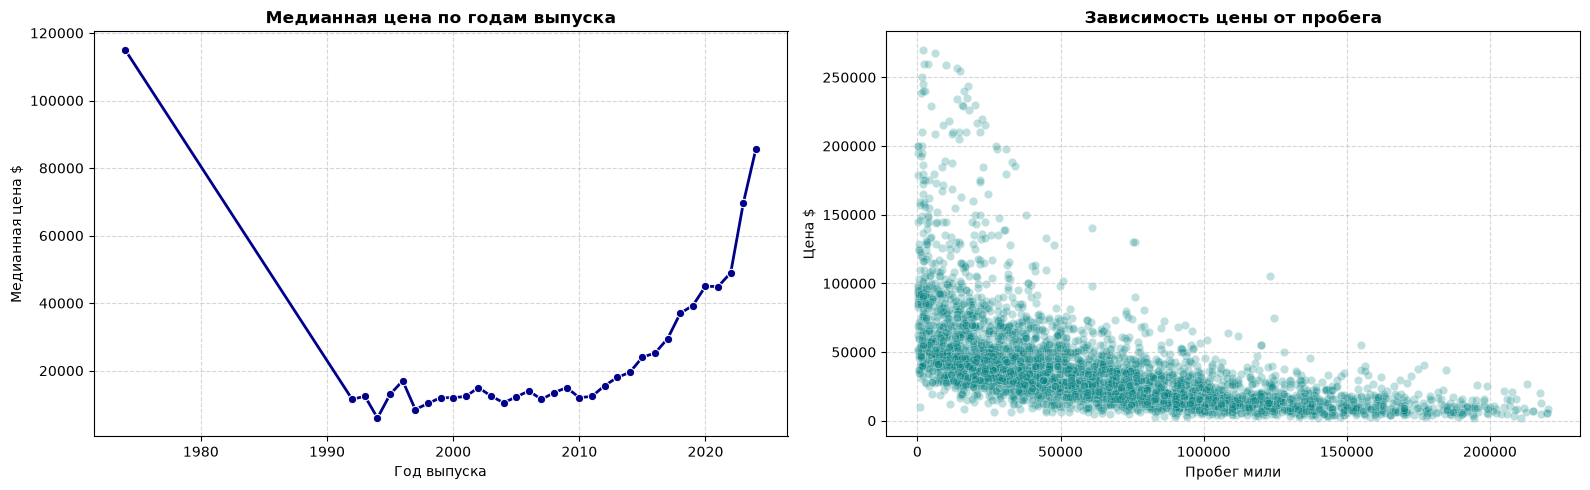

In [27]:
q99_milage = df_clean['milage'].quantile(0.99)

df_filtered = df_clean[
    (df_clean['price'] <= q99_price) & 
    (df_clean['milage'] <= q99_milage)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
year_price = df_filtered.groupby('model_year')['price'].median().reset_index()

sns.lineplot(
    data=year_price,
    x='model_year',
    y='price',
    marker='o',
    color='darkblue',
    linewidth=2,
    ax=axes[0],
)

axes[0].set_title('Медианная цена по годам выпуска', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Год выпуска')
axes[0].set_ylabel('Медианная цена $')
axes[0].grid(True, ls='--', alpha=0.5)

sns.scatterplot(
    data=df_filtered,
    x='milage',
    y='price',
    alpha=0.25,
    color='teal',
    ax=axes[1],
)

axes[1].set_title('Зависимость цены от пробега', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Пробег мили')
axes[1].set_ylabel('Цена $')
axes[1].grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Различия в ценах между авто с дтп и без

                                 accident  count   median          mean  \
0  At least 1 accident or damage reported   1080  22111.0  28719.134259   
1                           None reported   2847  35500.0  44074.097998   

       q25      q75  
0  12900.0  36075.0  
1  20000.0  53850.0  


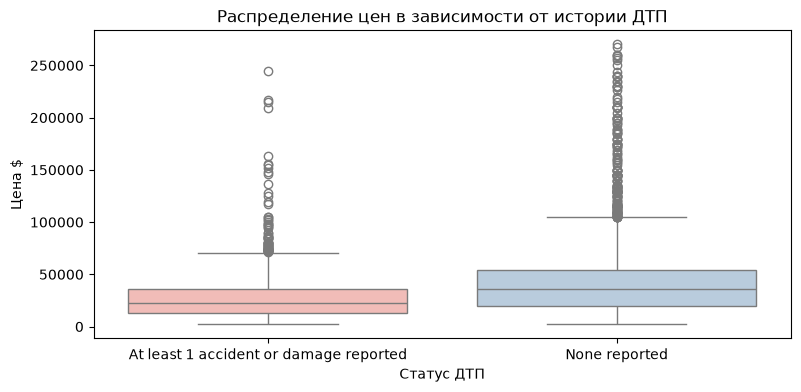

In [28]:
accident_stats = (
    df_filtered.groupby('accident')['price']
    .agg(
        count='count',
        median='median',
        mean='mean',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)
print(accident_stats)

plt.figure(figsize=(9, 4))
sns.boxplot(
    data=df_filtered,
    x='accident',
    y='price',
    hue='accident',
    palette='Pastel1',
    legend=False,
)
plt.title('Распределение цен в зависимости от истории ДТП')
plt.xlabel('Статус ДТП')
plt.ylabel('Цена $')
plt.show()

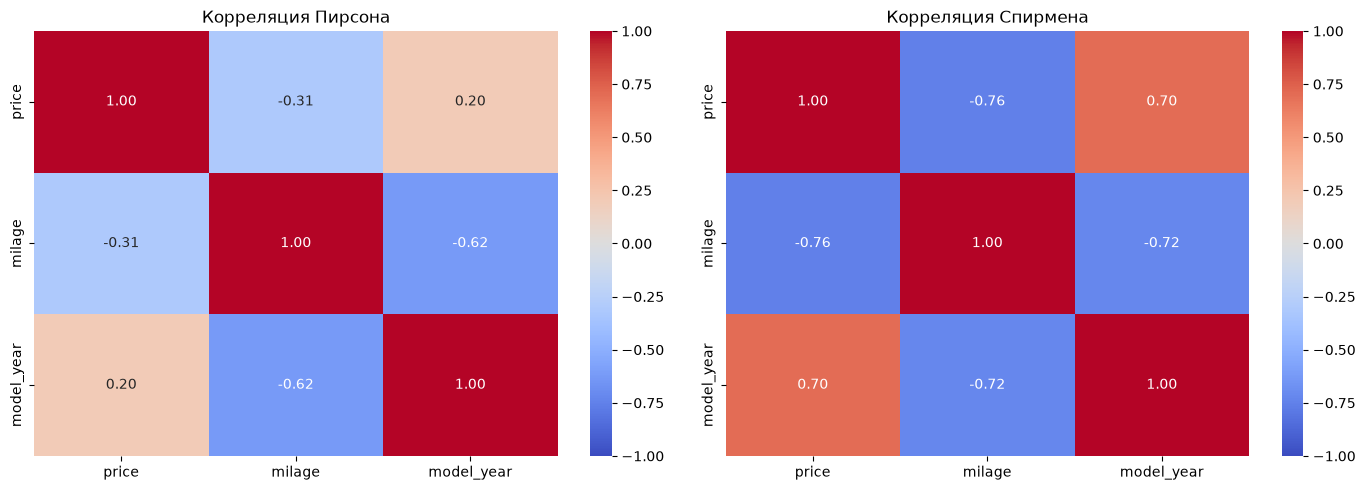

In [29]:
num_cols = ['price', 'milage', 'model_year']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

corr_p = df_clean[num_cols].corr(method='pearson')
sns.heatmap(
    corr_p,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    ax=axes[0],
)
axes[0].set_title('Корреляция Пирсона')


corr_s = df_clean[num_cols].corr(method='spearman')
sns.heatmap(
    corr_s,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title('Корреляция Спирмена')

plt.tight_layout()
plt.show()

## φk корреляция

 Корреляция не считалась на всем датасетете, поэтому я убрал `model`, `ext_col`, `int_col` и `engine`, в этих признаках очень много разных уникальных значений и φk будет требовать ресурсов больше чем потянет мой компьютер :(

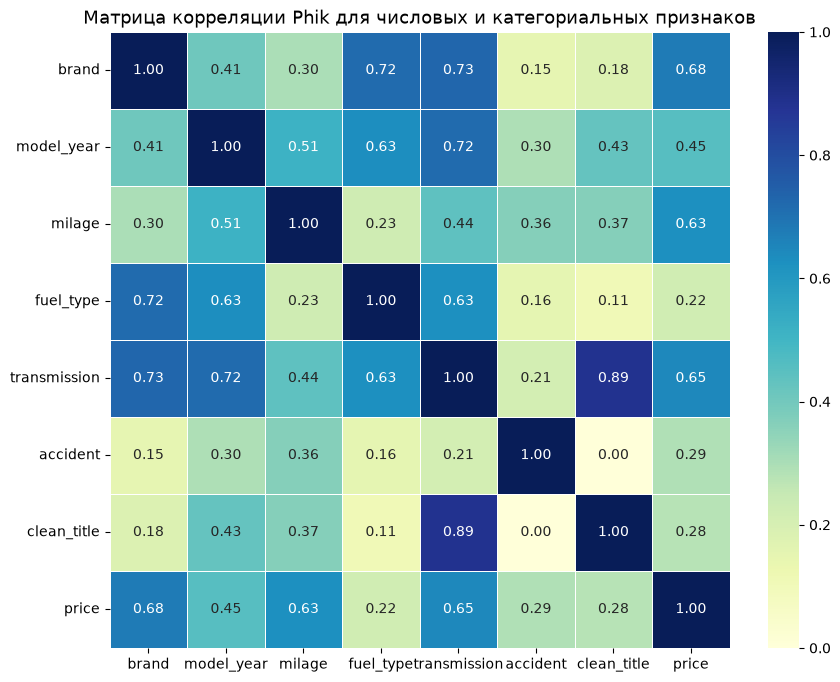

In [30]:
cols_for_phik = [
    'brand',
    'model_year',
    'milage',
    'fuel_type',
    'transmission',
    'accident',
    'clean_title',
    'price',
]

interval_cols = ['model_year', 'milage', 'price']

phik_matrix = df_filtered[cols_for_phik].phik_matrix(interval_cols=interval_cols)

plt.figure(figsize=(10, 8))
sns.heatmap(
    phik_matrix,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=0,
    vmax=1,
    linewidths=0.5,
)
plt.title('Матрица корреляции Phik для числовых и категориальных признаков',fontsize=13)
plt.show()

## Выводы по результатам

* Марки автомобилей: В датасете преобладают массовые бренды Ford, Chevrolet, BMW, Mercedes-Benz, Toyota
  
* Ранговая корреляция наглядно демонстрирует отрицательную связь цены с пробегом  и положительную с годом выпуска

 
* Корреляция $\phi_K$ показывает высокую нелинейную зависимость цены от марки и года модели, подтверждая, что класс, статус и современный год выпуска автомобиля определяют базовый уровень стоимости в большей степени, чем один лишь пробег

* Влияние ДТП: Автомобили с отметкой None reported имеют ощутимо более высокую медианную стоимость и межквартильный диапазон по сравнению с группой At least 1 accident or damage reported. Наличие ДТП снижает рыночную привлекательность и стоимость авто

## 7. Итоговые выводы

Сформулируйте итоговый отчёт по результатам EDA. В отчёте отразите:

**Качество данных:**
- Какие проблемы обнаружены?
- Как вы их решили?
- Что рекомендуете улучшить при сборе данных?

**Ключевые находки:**
- Самые интересные закономерности, аномалии и взаимосвязи

**Рекомендации:**
- На что стоит обратить внимание при дальнейшем анализе или построении ценовой модели


# Итоговый отчёт по результатам EDA

---

## 1. Качество данных

### Какие проблемы обнаружены?
* **Некорректные типы данных:** Числовые признаки `milage` и `price` хранились как текстовые, содержали спецсимволы (`$`, `mi.`), пробелы и запятые
* **Специфическая природа пропусков:**
  * `fuel_type` — 170 пропусков (4.24%): все пропуски пришлись на электромобили, у которых в описании двигателя значилось `Electric Motor`
  * `clean_title` — 596 пропусков (14.87%): признак содержал только отметку `Yes`, пропуск фактически означал отсутствие чистого свидетельства о регистрации
  * `accident` — 113 пропусков (2.82%): умеренно коррелировал с отсутствием чистого тайтла ($r_{\text{nullity}} \approx 0.40$).
* **Большой правый хвост и выбросы:** В целевой переменной `price` обнаружены экстремальные значения (до 3 000 000 $), из-за чего среднее арифметическое оказалось в разы выше медианы
* **Высокая уникальность категорий:** Признаки `engine`, `transmission`, `ext_col`, `int_col` и `model` содержат сотни уникальных текстовых значений

### Как вы их решили?
* Поля `milage` и `price` очищены от строковых символов (`$`, `mi.`, `,`) и приведены к типу `float`
* Пропуски в `fuel_type` заполнены значением `'Electric'` на основе данных поля `engine`
* Пропуски в `clean_title` заменены на явную категорию `'No'`
* Пропуски в `accident` реклассифицированы в категорию `'At least 1 accident or damage reported'` на основе логического анализа
* Сохранены все 4 009 записей и 12 признаков: пропуски устранены без удаления строк, что сохранило объём выборки

### Что рекомендуете улучшить при сборе данных?
* **Валидация типов на входе:** сохранять цену и пробег исключительно в числовом виде без знаков валют и единиц измерения
* **Фиксация бинарных признаков:** чекбоксы `clean_title` и `accident` должны явно записывать `True`/`False` в базу данных, избегая записи неотмеченных полей как `NULL`, также рекомендую добавить сбор данных о кол-во проишествий
* **Нормализация справочников:** внедрить фиксированные выпадающие списки для цветов, типов КПП и видов топлива вместо свободного текста

---

## 2. Ключевые находки

* **Нелинейная амортизация стоимости:** зависимость цены от возраста носит экспоненциальный характер. Автомобиль теряет основную часть стоимости в первые 5–7 лет, после чего кривая выполаживается. Для машин старше 25–30 лет наступает перелом тренда — в силу вступает коллекционная ценность дорогих автомобилей
* **Доминирование фактора бренда:** `brand` задаёт ценовой диапазон сильнее, чем пробег или история ДТП. Премиальные марки даже со значительным пробегом оцениваются выше нестарых бюджетных моделей в идеальном состоянии
* **Влияние юридической и аварийной истории:** автомобили без зарегистрированных ДТП и с чистым тайтлом показывают стабильно более высокую медианную цену и меньший разброс остаточной стоимости

---

## 3. Рекомендации по дальнейшему анализу и моделированию
  * Извлечь из текстового поля `engine` числовые параметры: объём в литрах и мощность в л.с.
  * Укрупнить категории в цветах кузова и салона до базовых цветовых палитр (Black, White, Silver, Red, ...).

## 4. Итоговые выводы

Датасет приведен в пригодное для обучения состояние: типы синхронизированы, пропуски логически восполнены без потерь данных. Главный вызов задачи — сильная ценовая асимметрия и сложная текстовая структура технических характеристик. Точность прогнозирования модели будет напрямую зависеть от качества извлечения числовых характеристик двигателя структуррирования цветовых палитр.